 # 05 Using a drive cycle (Multi-Model Comparison)

 PyBaMM provides a number of example drive cycles that define the instantaneous current which can be read in from csv files. We also install required dependencies.

In [1]:
%pip install "pybamm<=23.9" "numpy<2.0,>=1.26.4" "pandas<2.0" liionpack matplotlib scipy

# MAKE SURE YOU ARE ON PYTHON 3.11 NO NEWER

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pybamm
import liionpack as lp

# Enable inline plotting for Jupyter
%matplotlib inline


In [3]:
# Load all recorded columns; set N_SAMPLES=100 for a short smoke test.
# Increase N_CYCLE_REPEATS to study cumulative degradation over repeated cycles.
N_SAMPLES = None
N_CYCLE_REPEATS = 1

drive_cycle_path = "../../../../../../../workspaces/liionpacktesting/data/ioniq.csv"
full_cycle = pd.read_csv(drive_cycle_path, comment="#").to_numpy()
if N_SAMPLES is not None:
    full_cycle = full_cycle[:N_SAMPLES]

# The CSV columns are Time, Current, Voltage, SoC, and SoH.
drive_cycle = full_cycle[:, :2].copy()
cycle_dt = float(np.median(np.diff(drive_cycle[:, 0])))
cycle_duration = drive_cycle[-1, 0] - drive_cycle[0, 0] + cycle_dt
if N_CYCLE_REPEATS > 1:
    drive_cycle = np.vstack([
        np.column_stack((drive_cycle[:, 0] + repeat * cycle_duration, drive_cycle[:, 1]))
        for repeat in range(N_CYCLE_REPEATS)
    ])

 Let's have a look at the drive cycle. The first column is the time stamp and the second is the current.

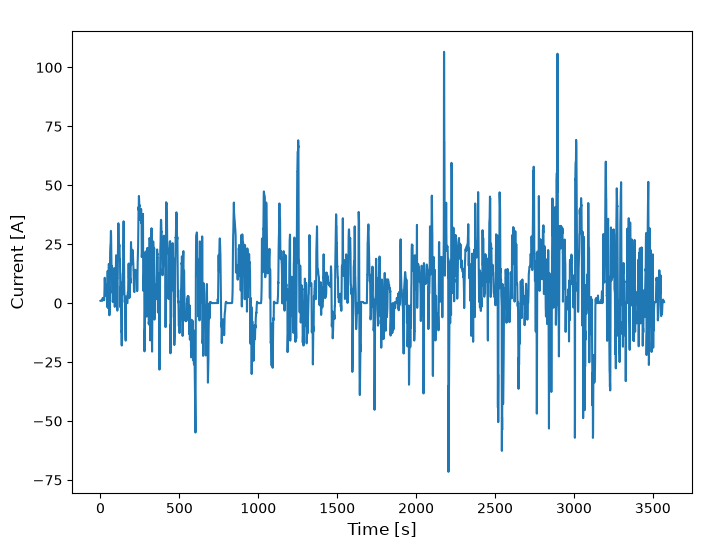

In [4]:
with plt.rc_context(lp.lp_context()):
    plt.rcParams['figure.facecolor'] = 'none'
    plt.rcParams['axes.facecolor'] = 'none'
    plt.rcParams['text.color'] = 'black'
    plt.rcParams['axes.labelcolor'] = 'black'
    plt.rcParams['xtick.color'] = 'black'
    plt.rcParams['ytick.color'] = 'black'
    plt.rcParams['axes.edgecolor'] = 'black'
    
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.plot(drive_cycle[:, 0], drive_cycle[:, 1])
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Current [A]")
    ax.set_title("Pack Drive Cycle Current")
    
    for spine in ax.spines.values():
        spine.set_edgecolor('black')
        spine.set_visible(True)
        
    plt.show()


 Set up our pack circuit, experiment, and parameters.

 We are using a 180s2p architecture.

In [5]:
Np = 2
Ns = 180
netlist = lp.setup_circuit(Np=Np, Ns=Ns, Rb=1e-4, Rc=1e-3, Ri=5e-2, V=4.0, I=14.0)

# Chen2020 is a placeholder cell parameter set, not an Ioniq 5 calibration.
parameter_values = pybamm.ParameterValues("Chen2020")
initial_soc = 0.965
nominal_cell_capacity = float(parameter_values["Nominal cell capacity [A.h]"])

# Enable SEI-driven degradation in the SPMe and DFN models.
aging_options = {
    "SEI": "ec reaction limited",
    "SEI film resistance": "distributed",
    "SEI porosity change": "true",
}
aging_variables = [
    "X-averaged negative total SEI thickness [m]",
    "Loss of capacity to negative SEI [A.h]",
    "Loss of capacity to positive SEI [A.h]",
]

# Pack-level experiment for liionpack
pack_experiment = pybamm.Experiment(
    [pybamm.step.current(drive_cycle)],
    period="0.5 second",
)
print(parameter_values["Upper voltage cut-off [V]"])
parameter_values.update({
    "Upper voltage cut-off [V]": 4.50,
    "Lower voltage cut-off [V]": 2.5,
})

4.2


 ## Model 1: SPM in liionpack

 Solves the standard Single Particle Model across all 360 cells as a non-aging voltage baseline.

In [6]:
def spm_sim_func(parameter_values):
    model = pybamm.lithium_ion.SPM()
    model = lp.add_events_to_model(model)
    return pybamm.Simulation(model, parameter_values=parameter_values, experiment=pack_experiment)

print("Solving SPM pack...")
output_spm = lp.solve(
    netlist=netlist,
    parameter_values=parameter_values,
    experiment=pack_experiment,
    initial_soc=initial_soc,
    sim_func=spm_sim_func,
)


Solving SPM pack...


Stepping simulation: 100%|██████████| 7144/7144 [17:34<00:00,  6.77it/s]


 ## Model 2: SEI-aging SPMe in liionpack

 Solves the Single Particle Model with Electrolyte across all 360 cells, with EC-reaction-limited SEI growth enabled.

In [7]:
def spme_sim_func(parameter_values):
    model = pybamm.lithium_ion.SPMe(options=aging_options)
    model = lp.add_events_to_model(model)
    return pybamm.Simulation(
        model,
        parameter_values=parameter_values,
        experiment=pack_experiment,
        solver=pybamm.CasadiSolver(mode="safe"),
    )

print(f"Solving SEI-aging SPMe pack for {len(drive_cycle)} input samples...")
output_spme = lp.solve(
    netlist=netlist,
    parameter_values=parameter_values,
    experiment=pack_experiment,
    initial_soc=initial_soc,
    sim_func=spme_sim_func,
    output_variables=aging_variables,
)

Solving SEI-aging SPMe pack for 7144 input samples...


Stepping simulation:  17%|█▋        | 1203/7144 [34:44<2:51:33,  1.73s/it]


 ## Model 3: SEI-aging DFN in pure PyBaMM

 Since liionpack cannot vectorize DFN across the netlist, we run DFN on a single cell and divide the pack current by Np so it matches the current through each parallel cell. The DFN uses the same SEI options and parameter set as the SPMe.

In [8]:
print("Solving SEI-aging lumped DFN...")
# Scale pack current for one cell in a 2P branch
cell_drive_cycle = drive_cycle.copy()
cell_drive_cycle[:, 1] = cell_drive_cycle[:, 1] / Np

dfn_experiment = pybamm.Experiment(
    [pybamm.step.current(cell_drive_cycle)],
    period="0.5 second",
)

dfn_model = pybamm.lithium_ion.DFN(options=aging_options)
dfn_sim = pybamm.Simulation(
    dfn_model,
    parameter_values=parameter_values,
    experiment=dfn_experiment,
    solver=pybamm.CasadiSolver(mode="safe"),
)
dfn_sol = dfn_sim.solve(initial_soc=initial_soc)

Solving SEI-aging lumped DFN...


 ## Voltage and SEI-Based SOH Comparison

 Compare pack-average cell voltages and the SEI-driven capacity-loss estimate for SPMe and DFN. The plotted SOH is calculated from the increase in capacity lost to SEI relative to the Chen2020 nominal cell capacity; it is not a complete Ioniq 5 SOH prediction.

In [9]:
# Extract pack voltage traces

t_lp = np.asarray(output_spm["Time [s]"])
v_spm = np.mean(output_spm["Terminal voltage [V]"], axis=1)
v_spme = np.mean(output_spme["Terminal voltage [V]"], axis=1)

In [10]:
# Align voltage and SEI-based SOH traces to the liionpack time vector

t_lp = np.asarray(t_lp)
v_spm = np.asarray(v_spm)
v_spme = np.asarray(v_spme)

# Build an SEI-capacity-loss SOH estimate relative to each model's initial state
sei_loss_spme = (
    np.asarray(output_spme["Loss of capacity to negative SEI [A.h]"])
    + np.asarray(output_spme["Loss of capacity to positive SEI [A.h]"])
)
soh_spme_cells = 100 * (
    1 - (sei_loss_spme - sei_loss_spme[0, :]) / nominal_cell_capacity
)
soh_spme = np.mean(soh_spme_cells, axis=1)

sei_loss_dfn = (
    np.asarray(dfn_sol["Loss of capacity to negative SEI [A.h]"].entries)
    + np.asarray(dfn_sol["Loss of capacity to positive SEI [A.h]"].entries)
)
soh_dfn_raw = 100 * (
    1 - (sei_loss_dfn - sei_loss_dfn[0]) / nominal_cell_capacity
)

t_dfn = np.asarray(dfn_sol["Time [s]"].entries)
v_dfn_raw = np.asarray(dfn_sol["Terminal voltage [V]"].entries)
order = np.argsort(t_dfn)
t_dfn = t_dfn[order]
v_dfn_raw = v_dfn_raw[order]
soh_dfn_raw = soh_dfn_raw[order]

# Shift DFN times to account for the time-index offset, then interpolate
dt = np.median(np.diff(t_lp))
t_dfn_shifted = t_dfn + dt
v_dfn = np.interp(t_lp, t_dfn_shifted, v_dfn_raw)
soh_dfn = np.interp(t_lp, t_dfn_shifted, soh_dfn_raw)

# Convert recorded pack voltage to per-series-group voltage; recorded SoH is in percent
t_recorded = np.asarray(full_cycle[:, 0], dtype=float)
v_recorded = np.asarray(full_cycle[:, 2], dtype=float) / Ns
soh_recorded = np.asarray(full_cycle[:, 4], dtype=float)
recorded_order = np.argsort(t_recorded)
t_recorded = t_recorded[recorded_order]
v_recorded = v_recorded[recorded_order]
soh_recorded = soh_recorded[recorded_order]

# Compare voltage errors only over the recorded time span
comparison_mask = (t_lp >= t_recorded[0]) & (t_lp <= t_recorded[-1])
t_compare = t_lp[comparison_mask]
v_recorded_compare = np.interp(t_compare, t_recorded, v_recorded)
v_spm_compare = v_spm[comparison_mask]
v_spme_compare = v_spme[comparison_mask]
v_dfn_compare = v_dfn[comparison_mask]

diff_spm = np.abs(v_spm_compare - v_recorded_compare) / v_recorded_compare * 100
diff_spme = np.abs(v_spme_compare - v_recorded_compare) / v_recorded_compare * 100
diff_dfn = np.abs(v_dfn_compare - v_recorded_compare) / v_recorded_compare * 100

print("--- Maximum Voltage Errors vs Recorded ---")
print(f"SPM:  {np.max(diff_spm):.4f}%")
print(f"SPMe: {np.max(diff_spme):.4f}%")
print(f"DFN:  {np.max(diff_dfn):.4f}%")
print("Final SPMe SEI-based SOH estimate:", f"{soh_spme[-1]:.6f}%")
print("Final DFN SEI-based SOH estimate:", f"{soh_dfn[-1]:.6f}%")
print("Typical pack dt:", dt)
print("Typical DFN dt:", np.median(np.diff(t_dfn)))

IndexError: boolean index did not match indexed array along dimension 0; dimension is 1204 but corresponding boolean dimension is 7144

In [ ]:
# Plot voltage, recorded-relative errors, and SEI-based SOH
with plt.rc_context(lp.lp_context()):
    plt.rcParams['figure.facecolor'] = 'none'
    plt.rcParams['axes.facecolor'] = 'none'
    plt.rcParams['text.color'] = 'black'
    plt.rcParams['axes.labelcolor'] = 'black'
    plt.rcParams['xtick.color'] = 'black'
    plt.rcParams['ytick.color'] = 'black'
    plt.rcParams['axes.edgecolor'] = 'black'
    fig, (ax1, ax2, ax3) = plt.subplots(
        3, 1, figsize=(10, 18),
        gridspec_kw={'height_ratios': [2, 1, 1]},
        sharex=True,
    )

    # Top plot: model and recorded cell voltage
    ax1.plot(t_lp, v_spm, label="SPM (Pack Average)", linestyle=':')
    ax1.plot(t_lp, v_spme, label="SPMe + SEI (Pack Average)", linestyle='--')
    ax1.plot(t_lp, v_dfn, label="DFN + SEI (Lumped Cell)", alpha=0.7)
    ax1.plot(
        t_recorded, v_recorded,
        label="Recorded (Per Series Group)", linestyle='-.', color="black",
    )
    ax1.set_ylabel("Cell Terminal Voltage [V]")
    ax1.set_title("Voltage Comparison Under Drive Cycle")
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    # Middle plot: voltage error relative to recorded measurements
    ax2.plot(t_compare, diff_spm, label="% Error SPM", color="blue")
    ax2.plot(t_compare, diff_spme, label="% Error SPMe", color="orange")
    ax2.plot(t_compare, diff_dfn, label="% Error DFN", color="green")
    ax2.set_ylabel("Error vs Recorded [%]")
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    # Bottom plot: modeled SEI-based SOH and recorded SoH
    ax3.plot(t_lp, soh_spme, label="SPMe SEI-based SOH", color="orange")
    ax3.plot(t_lp, soh_dfn, label="DFN SEI-based SOH", color="green")
    ax3.plot(
        t_recorded, soh_recorded,
        label="Recorded SoH (First Cycle)", linestyle='-.', color="black",
    )
    ax3.set_xlabel("Time [s]")
    ax3.set_ylabel("SOH [%]")
    ax3.legend()
    ax3.grid(True, alpha=0.3)

    for ax in [ax1, ax2, ax3]:
        for spine in ax.spines.values():
            spine.set_edgecolor('black')
            spine.set_visible(True)

    plt.tight_layout()
    plt.show()

 *The modeled SOH is an SEI-only estimate based on added capacity loss relative to the initial state; it excludes other mechanisms such as lithium plating and loss of active material. `Chen2020` is an LG M50 cell parameter set, not an Ioniq 5 calibration. Increase `N_CYCLE_REPEATS` to accumulate modeled aging, and replace the parameter set with validated Ioniq-cell data before interpreting the result as vehicle SOH. The recorded SoH trace covers only the original cycle.*